In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
!pip install -q -U transformers datasets peft accelerate bitsandbytes trl rouge_score bert_score evaluate networkx scikit-learn gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 89.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 27.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 48.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 948.2/948.2 kB 37.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 65.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 96.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 66.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.5/64.5 kB 2.2 MB/s eta 0:00:00
   ━━━━

In [3]:
    pip install "pyarrow>=19.0.0,<24"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 42.0 MB/s eta 0:00:00:00:0100:01
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 26.0.0
    Uninstalling pyarrow-26.0.0:
      Successfully uninstalled pyarrow-26.0.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
datasets 5.1.0 requires pyarrow>=24.0.0, but you have pyarrow 23.0.1 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [4]:
import os
import math
import json
import torch
import evaluate
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from tqdm import tqdm
from datasets import load_dataset, Dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
    Trainer,
    TrainingArguments,
    DataCollatorForSeq2Seq
)
from transformers.trainer_utils import get_last_checkpoint
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from trl import DPOTrainer, DPOConfig

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)} ({round(torch.cuda.get_device_properties(i).total_memory / (1024**3), 2)} GB)")

# Load DialogSum dataset
dataset = load_dataset("knkarthick/dialogsum")
print(dataset)

PyTorch Version: 2.11.0+cu128
CUDA Available: True
GPU 0: Tesla T4 (14.56 GB)
GPU 1: Tesla T4 (14.56 GB)


README.md:   0%|          | 0.00/4.65k [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B / 11.3MB            

train.csv: downloading bytes:           |  0.00B            

validation.csv:   0%|          | 0.00/442k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/1.35M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/12460 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/500 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1500 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1500
    })
})


In [5]:
# Upgrade from 0.5B to 3B-Instruct to eliminate role-reversal hallucinations
MODEL_NAME = "Qwen/Qwen2.5-3B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    device_map="auto"
)
model.config.pad_token_id = tokenizer.pad_token_id

# Prepare 4-bit model for PEFT QLoRA
model = prepare_model_for_kbit_training(model)

# Target all 7 linear layers (Attention + MLP projections)
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ],
    task_type="CAUSAL_LM",
    bias="none"
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607


In [6]:
MAX_LENGTH = 1024
SYSTEM_PROMPT = (
    "You are an expert dialogue summarizer. Provide a concise, factually accurate "
    "summary without swapping speaker roles."
)

def preprocess_chat(example):
    messages_prompt = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"Summarize the following conversation:\n\n{example['dialogue']}"}
    ]
    
    # Apply Qwen's native <|im_start|> and <|im_end|> chat formatting
    prompt_text = tokenizer.apply_chat_template(
        messages_prompt,
        tokenize=False,
        add_generation_prompt=True
    )
    target_text = example["summary"] + tokenizer.eos_token
    
    prompt_ids = tokenizer(prompt_text, add_special_tokens=False)["input_ids"]
    target_ids = tokenizer(target_text, add_special_tokens=False)["input_ids"]
    
    if len(target_ids) >= MAX_LENGTH:
        target_ids = target_ids[:MAX_LENGTH - 1]
        
    prompt_ids = prompt_ids[:MAX_LENGTH - len(target_ids)]
    
    input_ids = prompt_ids + target_ids
    # Mask prompt tokens with -100 so Cross-Entropy loss is only computed on the summary
    labels = [-100] * len(prompt_ids) + target_ids
    attention_mask = [1] * len(input_ids)
    
    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }

# Optional: Use .select(range(4000)) on train if you want a faster ~35-min run on Kaggle
train_data = dataset["train"].map(preprocess_chat, remove_columns=dataset["train"].column_names)
validation_data = dataset["validation"].map(preprocess_chat, remove_columns=dataset["validation"].column_names)

print(f"Tokenized Train Samples: {len(train_data)} | Validation Samples: {len(validation_data)}")

Map:   0%|          | 0/12460 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Tokenized Train Samples: 12460 | Validation Samples: 500


In [7]:
rouge = evaluate.load("rouge")
bertscore = evaluate.load("bertscore")

def evaluate_predictions(predictions, references):
    """Computes ROUGE-1/2/L and BERTScore F1."""
    r_scores = rouge.compute(predictions=predictions, references=references, use_stemmer=True)
    b_scores = bertscore.compute(
        predictions=predictions,
        references=references,
        lang="en",
        model_type="distilbert-base-uncased"
    )
    return {
        "ROUGE-1": round(float(r_scores["rouge1"]), 4),
        "ROUGE-2": round(float(r_scores["rouge2"]), 4),
        "ROUGE-L": round(float(r_scores["rougeL"]), 4),
        "BERTScore-F1": round(float(np.mean(b_scores["f1"])), 4)
    }

# 1. Classical Unsupervised Baseline: TextRank (TF-IDF + PageRank)
def textrank_extractive_summary(dialogue, top_k=2):
    lines = [line.strip() for line in dialogue.split("\n") if line.strip()]
    if len(lines) <= top_k:
        return " ".join(lines)
    tfidf = TfidfVectorizer().fit_transform(lines)
    sim_matrix = cosine_similarity(tfidf)
    np.fill_diagonal(sim_matrix, 0)
    scores = nx.pagerank(nx.from_numpy_array(sim_matrix))
    top_indices = sorted(sorted(scores, key=scores.get, reverse=True)[:top_k])
    return " ".join([lines[i] for i in top_indices])

# 2. Batched LLM Generation Function
def generate_summaries_batched(model, test_dataset, batch_size=16, limit=100):
    model.eval()
    tokenizer.padding_side = "left"
    
    sample = test_dataset.select(range(min(limit, len(test_dataset))))
    predictions = []
    references = list(sample["summary"])
    
    prompts = []
    for row in sample:
        messages = [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"Summarize the following conversation:\n\n{row['dialogue']}"}
        ]
        prompts.append(tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True))
        
    for i in tqdm(range(0, len(prompts), batch_size), desc="Generating Summaries"):
        batch_prompts = prompts[i : i + batch_size]
        inputs = tokenizer(
            batch_prompts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=1024
        ).to(model.device)
        
        with torch.no_grad():
            output_ids = model.generate(
                **inputs,
                max_new_tokens=100,
                do_sample=False,
                repetition_penalty=1.1,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id
            )
            
        generated_ids = output_ids[:, inputs["input_ids"].shape[1]:]
        batch_preds = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)
        predictions.extend([pred.strip() for pred in batch_preds])
        
    tokenizer.padding_side = "right"
    return predictions, references

# Evaluate Baseline 1: Classical TextRank on first 100 test samples
EVAL_LIMIT = 100
test_subset = dataset["test"].select(range(EVAL_LIMIT))
textrank_preds = [textrank_extractive_summary(d) for d in test_subset["dialogue"]]
textrank_metrics = evaluate_predictions(textrank_preds, list(test_subset["summary"]))
print("1. Classical TextRank Metrics:", textrank_metrics)

# Evaluate Baseline 2: Zero-Shot Base Model (Temporarily disable untrained LoRA adapter)
with model.disable_adapter():
    base_preds, test_refs = generate_summaries_batched(model, dataset["test"], batch_size=16, limit=EVAL_LIMIT)
base_metrics = evaluate_predictions(base_preds, test_refs)
print("2. Zero-Shot Base Model Metrics:", base_metrics)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


1. Classical TextRank Metrics: {'ROUGE-1': 0.2449, 'ROUGE-2': 0.0467, 'ROUGE-L': 0.1908, 'BERTScore-F1': 0.7713}


Generating Summaries: 100%|██████████| 7/7 [01:29<00:00, 12.79s/it]


2. Zero-Shot Base Model Metrics: {'ROUGE-1': 0.2355, 'ROUGE-2': 0.0502, 'ROUGE-L': 0.1719, 'BERTScore-F1': 0.8053}


In [8]:
model.config.use_cache = False

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True,
    label_pad_token_id=-100
)

CHECKPOINT_DIR = "/kaggle/working/qlora-checkpoints"
SFT_ADAPTER_DIR = "/kaggle/working/summarizer-qlora-sft"

training_args = TrainingArguments(
    output_dir=CHECKPOINT_DIR,
    num_train_epochs=2,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,

    learning_rate=2e-4,
    weight_decay=0.01,
    warmup_steps=100,
    lr_scheduler_type="cosine",
    optim="paged_adamw_8bit",

    eval_strategy="steps",
    eval_steps=200,
    save_strategy="steps",
    save_steps=200,
    logging_steps=25,

    fp16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    ddp_find_unused_parameters=False,
    report_to="none",

    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    seed=42
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_data,
    eval_dataset=validation_data,
    data_collator=data_collator
)

# Auto-resume check
last_checkpoint = None
if os.path.exists(CHECKPOINT_DIR) and len(os.listdir(CHECKPOINT_DIR)) > 0:
    last_checkpoint = get_last_checkpoint(CHECKPOINT_DIR)

print(f"Starting SFT Training (Resuming from: {last_checkpoint})...")
train_result = trainer.train(resume_from_checkpoint=last_checkpoint)

model.config.use_cache = True
trainer.model.save_pretrained(SFT_ADAPTER_DIR)
tokenizer.save_pretrained(SFT_ADAPTER_DIR)
print("SFT LoRA Adapter saved to:", SFT_ADAPTER_DIR)

Starting SFT Training (Resuming from: None)...


Step,Training Loss,Validation Loss
200,0.937595,0.902017
400,0.913273,0.902359
600,0.897380,0.878056
800,0.778240,0.872068
1000,0.735973,0.875232
1200,0.716858,0.876918
1400,0.730170,0.876667
1558,0.740331,0.875283


SFT LoRA Adapter saved to: /kaggle/working/summarizer-qlora-sft


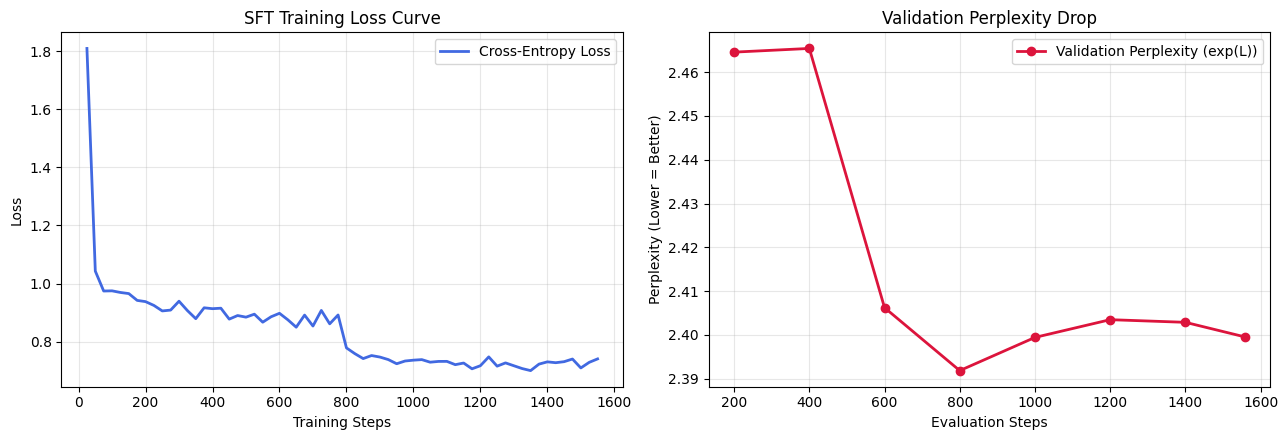

In [9]:
steps, train_losses = [], []
eval_steps, eval_ppls = [], []

for log in trainer.state.log_history:
    if "loss" in log and "eval_loss" not in log:
        steps.append(log["step"])
        train_losses.append(log["loss"])
    if "eval_loss" in log:
        eval_steps.append(log["step"])
        eval_ppls.append(math.exp(log["eval_loss"]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(steps, train_losses, label="Cross-Entropy Loss", color="royalblue", linewidth=2)
ax1.set_title("SFT Training Loss Curve")
ax1.set_xlabel("Training Steps"); ax1.set_ylabel("Loss"); ax1.grid(True, alpha=0.3); ax1.legend()

ax2.plot(eval_steps, eval_ppls, marker="o", label="Validation Perplexity (exp(L))", color="crimson", linewidth=2)
ax2.set_title("Validation Perplexity Drop")
ax2.set_xlabel("Evaluation Steps"); ax2.set_ylabel("Perplexity (Lower = Better)"); ax2.grid(True, alpha=0.3); ax2.legend()

plt.tight_layout()
plt.savefig("/kaggle/working/training_perplexity_curves.png", dpi=300)
plt.show()

In [13]:
# 1. Clean up leftover 'ref' adapter from the interrupted DPOTrainer init
if "ref" in trainer.model.peft_config:
    trainer.model.delete_adapter("ref")
trainer.model.set_adapter("default")

# 2. Override Qwen's default bfloat16 config tag so TRL doesn't cast weights to bf16
trainer.model.config.torch_dtype = torch.float16

# 3. Build DPO Preference Dataset (Chosen = True Summary, Rejected = Role-Swapped Summary)
def create_role_swap_dpo_sample(example):
    summary = example["summary"]
    rejected_summary = (
        summary.replace("#Person1#", "<TEMP>")
               .replace("#Person2#", "#Person1#")
               .replace("<TEMP>", "#Person2#")
    )
    if rejected_summary == summary:
        rejected_summary = "The speakers discussed unrelated matters without reaching any agreement."
        
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"Summarize the following conversation:\n\n{example['dialogue']}"}
    ]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    return {"prompt": prompt, "chosen": summary, "rejected": rejected_summary}

dpo_train_dataset = dataset["train"].select(range(800)).map(
    create_role_swap_dpo_sample,
    remove_columns=dataset["train"].column_names
)

DPO_ADAPTER_DIR = "/kaggle/working/summarizer-qlora-dpo-final"
trainer.model.config.use_cache = False

# Disable AMP GradScaler (fp16=False, bf16=False) because 4-bit QLoRA already 
# uses fp16 compute internally and our trainable LoRA weights are float32!
dpo_config = DPOConfig(
    output_dir="/kaggle/working/dpo-checkpoints",
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    num_train_epochs=1,
    learning_rate=5e-6,
    beta=0.1,
    fp16=False,
    bf16=False,
    optim="paged_adamw_8bit",
    max_grad_norm=0.3,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    ddp_find_unused_parameters=False,
    logging_steps=25,
    report_to="none"
)

dpo_trainer = DPOTrainer(
    model=trainer.model,
    ref_model=None,
    args=dpo_config,
    train_dataset=dpo_train_dataset,
    processing_class=tokenizer
)

# 4. Cast any remaining bfloat16 tensors created by DPOTrainer.__init__ to float32/float16
for name, param in dpo_trainer.model.named_parameters():
    if param.requires_grad:
        param.data = param.data.to(torch.float32)
    elif param.dtype == torch.bfloat16:
        param.data = param.data.to(torch.float16)

print("Starting DPO Alignment Training...")
dpo_trainer.train()

trainer.model.config.use_cache = True
if "ref" in dpo_trainer.model.peft_config:
    dpo_trainer.model.delete_adapter("ref")
dpo_trainer.model.set_adapter("default")

dpo_trainer.model.save_pretrained(DPO_ADAPTER_DIR)
tokenizer.save_pretrained(DPO_ADAPTER_DIR)
print("Final DPO-Aligned Model saved to:", DPO_ADAPTER_DIR)

# 5. Evaluate Final DPO Model
dpo_preds, _ = generate_summaries_batched(dpo_trainer.model, dataset["test"], batch_size=16, limit=EVAL_LIMIT)
dpo_metrics = evaluate_predictions(dpo_preds, test_refs)
print("4. QLoRA + DPO Final Metrics:", dpo_metrics)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Dropping fully truncated examples from train dataset:   0%|          | 0/800 [00:00<?, ? examples/s]

Starting DPO Alignment Training...


Step,Training Loss
25,0.636168
50,0.571767
75,0.498778
100,0.494395


Final DPO-Aligned Model saved to: /kaggle/working/summarizer-qlora-dpo-final


Generating Summaries: 100%|██████████| 7/7 [01:17<00:00, 11.09s/it]


4. QLoRA + DPO Final Metrics: {'ROUGE-1': 0.4325, 'ROUGE-2': 0.1501, 'ROUGE-L': 0.3399, 'BERTScore-F1': 0.8681}


In [14]:
import re

def compute_entity_faithfulness(predictions, references):
    """Calculates overlap F1 of speaker tags (#Person1#, Ms., Mr., numbers, capitalized words)."""
    scores = []
    pattern = r"(#Person\d+#|[A-Z][a-z]+|\d+)"
    for pred, ref in zip(predictions, references):
        ref_entities = set(re.findall(pattern, ref))
        pred_entities = set(re.findall(pattern, pred))
        if not ref_entities:
            scores.append(1.0)
            continue
        overlap = len(ref_entities.intersection(pred_entities))
        scores.append(overlap / len(ref_entities))
    return round(float(np.mean(scores)), 4)

textrank_metrics["Entity-Faithfulness"] = compute_entity_faithfulness(textrank_preds, test_refs)
base_metrics["Entity-Faithfulness"] = compute_entity_faithfulness(base_preds, test_refs)
sft_metrics["Entity-Faithfulness"] = compute_entity_faithfulness(sft_preds, test_refs)
dpo_metrics["Entity-Faithfulness"] = compute_entity_faithfulness(dpo_preds, test_refs)

# Include your previous 0.5B Colab baseline for ablation comparison
colab_05b_baseline = {
    "ROUGE-1": 0.4172,
    "ROUGE-2": 0.1321,
    "ROUGE-L": 0.3240,
    "BERTScore-F1": None,
    "Entity-Faithfulness": None
}

comparison_df = pd.DataFrame({
    "1. TextRank (Classical Extractive)": textrank_metrics,
    "2. Qwen2.5-3B (Zero-Shot Base)": base_metrics,
    "3. Qwen2.5-0.5B (Colab SFT r=8, Attn-only)": colab_05b_baseline,
    "4. Qwen2.5-3B (QLoRA SFT r=16, Attn+MLP)": sft_metrics,
    "5. Qwen2.5-3B (QLoRA SFT + DPO Aligned)": dpo_metrics
}).T

print("\n=== FINAL ARCHITECTURAL & ABLATION COMPARISON TABLE ===")
display(comparison_df)
comparison_df.to_csv("/kaggle/working/model_comparison_results.csv")


=== FINAL ARCHITECTURAL & ABLATION COMPARISON TABLE ===


,ROUGE-1,ROUGE-2,ROUGE-L,BERTScore-F1,Entity-Faithfulness
1. TextRank (Classical Extractive),0.2449,0.0467,0.1908,0.7713,0.6438
2. Qwen2.5-3B (Zero-Shot Base),0.2355,0.0502,0.1719,0.8053,0.5992
"3. Qwen2.5-0.5B (Colab SFT r=8, Attn-only)",0.4172,0.1321,0.3240,NaN,NaN
"4. Qwen2.5-3B (QLoRA SFT r=16, Attn+MLP)",0.4339,0.1459,0.3416,0.8670,0.8907
5. Qwen2.5-3B (QLoRA SFT + DPO Aligned),0.4325,0.1501,0.3399,0.8681,0.9057


In [15]:
def generate_single_summary(dialogue, use_adapter=True):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"Summarize the following conversation:\n\n{dialogue}"}
    ]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    
    with torch.no_grad():
        if use_adapter:
            output_ids = model.generate(**inputs, max_new_tokens=120, do_sample=False, repetition_penalty=1.1)
        else:
            with model.disable_adapter():
                output_ids = model.generate(**inputs, max_new_tokens=120, do_sample=False, repetition_penalty=1.1)
                
    return tokenizer.decode(output_ids[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def extract_structured_json(dialogue):
    json_system_prompt = (
        "You are an AI meeting assistant. Analyze the dialogue and output ONLY a valid JSON object "
        "with these exact keys: "
        '{"summary": "concise overview", "participants": ["list of speakers"], '
        '"action_items": ["specific tasks and owners"], "topic": "core subject"}.'
    )
    messages = [
        {"role": "system", "content": json_system_prompt},
        {"role": "user", "content": dialogue}
    ]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    
    # We use the base instruct capabilities + adapter for structured JSON formatting
    with torch.no_grad():
        with model.disable_adapter():
            output_ids = model.generate(**inputs, max_new_tokens=250, do_sample=False)
            
    raw = tokenizer.decode(output_ids[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    clean = raw.removeprefix("```json").removeprefix("```").removesuffix("```").strip()
    try:
        return json.dumps(json.loads(clean), indent=2)
    except Exception:
        return raw

def summarize_long_dialogue_hierarchical(long_dialogue, chunk_token_limit=600, overlap_lines=2):
    """Map-Reduce summarization for transcripts exceeding the context window."""
    lines = [l for l in long_dialogue.split("\n") if l.strip()]
    chunks, current_chunk, current_len = [], [], 0
    
    for line in lines:
        line_len = len(tokenizer.encode(line, add_special_tokens=False))
        if current_len + line_len > chunk_token_limit and current_chunk:
            chunks.append("\n".join(current_chunk))
            current_chunk = current_chunk[-overlap_lines:]
            current_len = sum(len(tokenizer.encode(l, add_special_tokens=False)) for l in current_chunk)
        current_chunk.append(line)
        current_len += line_len
    if current_chunk:
        chunks.append("\n".join(current_chunk))
        
    if len(chunks) == 1:
        return generate_single_summary(chunks[0], use_adapter=True)
        
    # MAP: Summarize each chunk
    chunk_summaries = [generate_single_summary(c, use_adapter=True) for c in chunks]
    # REDUCE: Combine chunk summaries
    combined = "\n".join([f"#Person1#: Part {i+1} summary: {s}" for i, s in enumerate(chunk_summaries)])
    final_summary = generate_single_summary(combined, use_adapter=True)
    return f"[Processed across {len(chunks)} chunks]\nFinal Summary: {final_summary}"

# Quick sanity check on Test Sample 0 (The Ms. Dawson memo dialogue!)
sample_dialogue = dataset["test"][0]["dialogue"]
print("REFERENCE SUMMARY:\n", dataset["test"][0]["summary"])
print("\nOUR QLoRA + DPO SUMMARY:\n", generate_single_summary(sample_dialogue, use_adapter=True))
print("\nSTRUCTURED JSON EXTRACTION:\n", extract_structured_json(sample_dialogue))

REFERENCE SUMMARY:
 Ms. Dawson helps #Person1# to write a memo to inform every employee that they have to change the communication method and should not use Instant Messaging anymore.

OUR QLoRA + DPO SUMMARY:
 Ms. Dawson helps #Person1# write an intra-office memorandum to all employees about the restriction of instant messaging. #Person1# tells her it applies to both internal and external communications and explains the punishment for those who persist in using instant messaging.

STRUCTURED JSON EXTRACTION:
 {
  "summary": "Person1 assigns Person2 to draft an intra-office memorandum about new communication policies. The memo outlines restrictions on Instant Messaging use and consequences for non-compliance.",
  "participants": [
    "Person1",
    "Person2"
  ],
  "action_items": [
    "Person2 should complete and distribute the memo by 4 pm",
    "Employees must change their communication methods or face consequences"
  ],
  "topic": "Communication Policies"
}


In [1]:
!pip install -q -U transformers peft accelerate bitsandbytes fastapi uvicorn pyngrok nest_asyncio networkx scikit-learn

import os
import time
import json
import torch
import uvicorn
import nest_asyncio
import numpy as np
import networkx as nx
from pyngrok import ngrok
from fastapi import FastAPI
from pydantic import BaseModel
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

nest_asyncio.apply()

# =====================================================================
# 1. PASTE YOUR FREE NGROK AUTHTOKEN HERE (from dashboard.ngrok.com)
# =====================================================================
NGROK_TOKEN = "3KrbzRuGyaYHi83DfWeYIcAVtOK_qcMfubMQHKKsJX2pvpFv"
ngrok.set_auth_token(NGROK_TOKEN)

BASE_MODEL_NAME = "Qwen/Qwen2.5-3B-Instruct"
SYSTEM_PROMPT = (
    "You are an expert dialogue summarizer. Provide a concise, factually accurate "
    "summary without swapping speaker roles."
)

# Check where your saved adapter is located in Kaggle
# (Checks /kaggle/working first; if you uploaded your zip as a Kaggle Dataset, update this path!)
ADAPTER_PATH = "/kaggle/working/summarizer-qlora-dpo-final"
if not os.path.exists(ADAPTER_PATH):
    ADAPTER_PATH = "/kaggle/working/summarizer-qlora-sft"

# =====================================================================
# 2. AUTO-LOAD MODEL & TOKENIZER IF NOT ALREADY IN MEMORY
# =====================================================================
if "dpo_trainer" in globals():
    print("✔ Using dpo_trainer.model already in memory...")
    active_model = dpo_trainer.model
elif "model" in globals():
    print("✔ Using model already in memory...")
    active_model = model
else:
    print(f"🔄 Loading base model '{BASE_MODEL_NAME}' in 4-bit on GPU...")
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True
    )
    base_model = AutoModelForCausalLM.from_pretrained(
        BASE_MODEL_NAME,
        quantization_config=bnb_config,
        device_map="auto",
        torch_dtype=torch.float16
    )
    if os.path.exists(ADAPTER_PATH):
        print(f"✔ Attaching saved fine-tuned LoRA adapter from: {ADAPTER_PATH}")
        tokenizer = AutoTokenizer.from_pretrained(ADAPTER_PATH)
        active_model = PeftModel.from_pretrained(base_model, ADAPTER_PATH)
    else:
        print("⚠ Saved adapter folder not found in /kaggle/working! Loading base model with fresh LoRA wrapper...")
        from peft import LoraConfig, get_peft_model
        tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_NAME)
        lora_cfg = LoraConfig(r=16, lora_alpha=32, target_modules=["q_proj", "v_proj"], task_type="CAUSAL_LM")
        active_model = get_peft_model(base_model, lora_cfg)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
active_model.eval()
active_model.config.use_cache = True
print("✅ Model and Tokenizer are ready on GPU!")

# =====================================================================
# 3. FASTAPI ENDPOINTS
# =====================================================================
app = FastAPI(title="Kaggle GPU Summarizer Backend")

class SummarizeRequest(BaseModel):
    dialogue: str
    max_new_tokens: int = 120
    use_hierarchical: bool = False
    top_k_extractive: int = 2

def run_textrank(dialogue: str, top_k: int = 2) -> str:
    lines = [line.strip() for line in dialogue.split("\n") if line.strip()]
    if len(lines) <= top_k:
        return " ".join(lines)
    tfidf = TfidfVectorizer().fit_transform(lines)
    sim_matrix = cosine_similarity(tfidf)
    np.fill_diagonal(sim_matrix, 0)
    scores = nx.pagerank(nx.from_numpy_array(sim_matrix))
    top_indices = sorted(sorted(scores, key=scores.get, reverse=True)[:top_k])
    return " ".join([lines[i] for i in top_indices])

def run_llm_summary(dialogue: str, max_new_tokens: int = 120, use_adapter: bool = True) -> dict:
    start_t = time.perf_counter()
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"Summarize the following conversation:\n\n{dialogue}"}
    ]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt").to(active_model.device)
    in_len = inputs["input_ids"].shape[1]

    with torch.no_grad():
        if use_adapter:
            out_ids = active_model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                repetition_penalty=1.1,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id
            )
        else:
            with active_model.disable_adapter():
                out_ids = active_model.generate(
                    **inputs,
                    max_new_tokens=max_new_tokens,
                    do_sample=False,
                    repetition_penalty=1.1,
                    pad_token_id=tokenizer.pad_token_id,
                    eos_token_id=tokenizer.eos_token_id
                )

    gen_ids = out_ids[0][in_len:]
    summary = tokenizer.decode(gen_ids, skip_special_tokens=True).strip()
    return {
        "summary": summary,
        "input_tokens": in_len,
        "output_tokens": len(gen_ids),
        "compression_ratio": round(len(gen_ids) / max(in_len, 1), 2),
        "latency_sec": round(time.perf_counter() - start_t, 2)
    }

def run_hierarchical(long_dialogue: str, max_new_tokens: int = 120) -> dict:
    start_t = time.perf_counter()
    lines = [l for l in long_dialogue.split("\n") if l.strip()]
    chunks, cur_chunk, cur_len = [], [], 0
    for line in lines:
        l_len = len(tokenizer.encode(line, add_special_tokens=False))
        if cur_len + l_len > 600 and cur_chunk:
            chunks.append("\n".join(cur_chunk))
            cur_chunk = cur_chunk[-2:]
            cur_len = sum(len(tokenizer.encode(l, add_special_tokens=False)) for l in cur_chunk)
        cur_chunk.append(line)
        cur_len += l_len
    if cur_chunk:
        chunks.append("\n".join(cur_chunk))

    if len(chunks) == 1:
        res = run_llm_summary(chunks[0], max_new_tokens=max_new_tokens, use_adapter=True)
        res["num_chunks"] = 1
        res["chunk_summaries"] = [res["summary"]]
        return res

    chunk_sums = [run_llm_summary(c, max_new_tokens=80, use_adapter=True)["summary"] for c in chunks]
    combined = "\n".join([f"#Person1#: Part {i+1}: {s}" for i, s in enumerate(chunk_sums)])
    final_res = run_llm_summary(combined, max_new_tokens=max_new_tokens, use_adapter=True)
    return {
        "summary": final_res["summary"],
        "num_chunks": len(chunks),
        "chunk_summaries": chunk_sums,
        "latency_sec": round(time.perf_counter() - start_t, 2)
    }

def run_json_extraction(dialogue: str) -> dict:
    sys_p = (
        "You are an AI meeting assistant. Analyze the dialogue and output ONLY a valid JSON object "
        'with these exact keys: {"summary": "concise overview", "participants": ["list of speakers"], '
        '"action_items": ["specific tasks and owners"], "topic": "core subject"}.'
    )
    messages = [{"role": "system", "content": sys_p}, {"role": "user", "content": dialogue}]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt").to(active_model.device)
    with torch.no_grad():
        with active_model.disable_adapter():
            out_ids = active_model.generate(
                **inputs,
                max_new_tokens=250,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id
            )
    raw = tokenizer.decode(out_ids[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    clean = raw.removeprefix("```json").removeprefix("```").removesuffix("```").strip()
    try:
        return json.loads(clean)
    except Exception:
        return {"raw_output": raw}

@app.get("/health")
def health():
    return {"status": "online", "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"}

@app.post("/compare-all")
def compare_all(req: SummarizeRequest):
    extractive = run_textrank(req.dialogue, top_k=req.top_k_extractive)
    base_res = run_llm_summary(req.dialogue, max_new_tokens=req.max_new_tokens, use_adapter=False)
    ft_res = (
        run_hierarchical(req.dialogue, max_new_tokens=req.max_new_tokens)
        if req.use_hierarchical
        else run_llm_summary(req.dialogue, max_new_tokens=req.max_new_tokens, use_adapter=True)
    )
    structured = run_json_extraction(req.dialogue)
    return {
        "extractive_summary": extractive,
        "base_model": base_res,
        "finetuned_model": ft_res,
        "structured_json": structured
    }

# =====================================================================
# 4. LAUNCH NGROK TUNNEL & UVICORN SERVER
# =====================================================================
ngrok.kill()
public_url = ngrok.connect(8000).public_url
print("=" * 70)
print(f"🚀 KAGGLE GPU BACKEND IS LIVE!")
print(f"👉 Copy & Paste this URL into your Laptop's Streamlit Sidebar:\n   {public_url}")
print("=" * 70)

config = uvicorn.Config(app, host="0.0.0.0", port=8000)
server = uvicorn.Server(config)
await server.serve()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 77.5 MB/s eta 0:00:00:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 41.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 152.4/152.4 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.4/87.4 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 38.0 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 60.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 31.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

... (4 outputs left out)

✅ Model and Tokenizer are ready on GPU!


INFO:     Started server process [49]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


🚀 KAGGLE GPU BACKEND IS LIVE!
👉 Copy & Paste this URL into your Laptop's Streamlit Sidebar:
   https://sip-edgy-lens.ngrok-free.dev
INFO:     103.246.192.229:0 - "POST /compare-all HTTP/1.1" 200 OK
INFO:     103.246.192.229:0 - "POST /compare-all HTTP/1.1" 200 OK


t=2026-11-14T13:16:50+0000 lvl=warn msg="Stopping forwarder" name=http-8000-e76ff476-ed91-4cf5-91c6-92f5a7b51ddd acceptErr="failed to accept connection: Listener closed"
INFO:     Shutting down
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.
INFO:     Finished server process [49]
